# v6 analysis A (GPU 0): Q2 + fix runs, improved numbers, lesion
**Before running:** stop the two training notebooks (Kernel → Interrupt). The last finished phase is already saved. GPU 0 must be free.
Then **Run All**. About 30–45 min. Analysis B (GPU 1) can run at the same time.

1. Analysis pass on the two new runs (as in v5): activations, correlations, matching at every transition → `analysis/v5/<run>/`.
2. `analyze_v6.py` (CPU, 1 min): all numbers at τ 0.2 and with a size-matched self, excess over pure noise, 95% intervals, encoder vs decoder, membership, training curves.
3. Lesion (mean-ablation, as in v5) on the new runs vs their references.

In [1]:
import os, sys, glob, json, time, subprocess
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    """Make sure runs/<run>/ckpt/pXXX_*.pt exists for each phase (download from HF if missing)."""
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("not on HF:", run, ph)

def run(*cmd):
    """Run a script and show its output here, line by line."""
    p = subprocess.Popen([sys.executable, "-u", *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

def phases_of(run):
    return sorted(int(os.path.basename(p)[1:4]) for p in glob.glob(f"runs/{run}/ckpt/p*.pt"))

FIX, Q2 = "v6_cont_noise0.0007_from60", "v6_hi_push0.6_from30"
REF_C, REF_H = "v4b_continual_s0", "v4b_only_hi_s0"
for r in [FIX, Q2]:
    print(f"{r:<30} trained phases: {[p for p in phases_of(r) if p > (60 if r == FIX else 30)]}")
for r in [REF_C, REF_H]:
    print(f"{r:<30} analysis files in repo: {len(glob.glob(f'analysis/v5/{r}/p*.npz'))} (should be ~90)")

v6_cont_noise0.0007_from60     trained phases: [61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86]
v6_hi_push0.6_from30           trained phases: [31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58]
v4b_continual_s0               analysis files in repo: 87 (should be ~90)
v4b_only_hi_s0                 analysis files in repo: 91 (should be ~90)


## 1. Analysis pass on the new runs (~30 s per checkpoint)

In [2]:
for r in [FIX, Q2]:
    run("analysis_v5_compute.py", "--run", r, "--gpu", GPU)

v6_cont_noise0.0007_from60: 27 checkpoints -> /workspace/shreshth/analysis/v5/v6_cont_noise0.0007_from60
  phase  60 (ar) done in 15s | ETA 7 min
  phase  61 (hi) done in 16s | ETA 7 min
  phase  62 (zh) done in 16s | ETA 6 min
  phase  63 (ar) done in 16s | ETA 6 min
  phase  64 (hi) done in 16s | ETA 6 min
  phase  65 (zh) done in 16s | ETA 6 min
  phase  66 (ar) done in 16s | ETA 5 min
  phase  67 (hi) done in 16s | ETA 5 min
  phase  68 (zh) done in 16s | ETA 5 min
  phase  69 (ar) done in 16s | ETA 5 min
  phase  70 (hi) done in 16s | ETA 4 min
  phase  71 (zh) done in 16s | ETA 4 min
  phase  72 (ar) done in 16s | ETA 4 min
  phase  73 (hi) done in 16s | ETA 3 min
  phase  74 (zh) done in 16s | ETA 3 min
  phase  75 (ar) done in 16s | ETA 3 min
  phase  76 (hi) done in 16s | ETA 3 min
  phase  77 (zh) done in 16s | ETA 2 min
  phase  78 (ar) done in 17s | ETA 2 min
  phase  79 (hi) done in 17s | ETA 2 min
  phase  80 (zh) done in 17s | ETA 2 min
  phase  81 (ar) done in 17s | ETA

## 2. Improved numbers and figures
How to read **figure A**: x = how much the network moved at a transition; y = relative gap. Dashed lines = what pure noise gives on that network.
Same x, star above its own dashed line → the self is protected more than chance; below → hit harder than chance.
The question for the Q2 push run (green): does it sit where the continual switches sit (below their noise line), or where Hindi drift sits (above)?

In [3]:
run("analyze_v6.py")
print(open("analysis/v6/summary.txt").read())

runs found: ['continual (ref)', 'Hindi only (ref)', 'v6_cont_noise0.0007_from60', 'v6_hi_push0.6_from30']
  continual (ref): done
  Hindi only (ref): done
  v6_cont_noise0.0007_from60: done
  v6_hi_push0.6_from30: done
self = biggest group of MLP neurons. fixed: tau 0.2 for every layer. sized: per checkpoint, tau where the biggest group = 40% of the layer.
One number per switch = mean over the 8 MLP layers; table = mean over switches in the window (switch counted by its to_phase).
rel gap = (task - self)/task, from the window means. excess = rel gap minus pure noise of the same size on the same kind of network
(continual curve for continual + fix runs, Hindi curve for Hindi + push runs). [..] = 95% bootstrap interval over switches.

===== self: fixed =====
run                                           window   n   task   self  rel gap          [95%]  excess          [95%]  size  stays   IoU
continual (ref)                                 2-60  59   48.7   41.5    14.7%   [ 14.4, 15.1] 

A_q2_movement_vs_gap


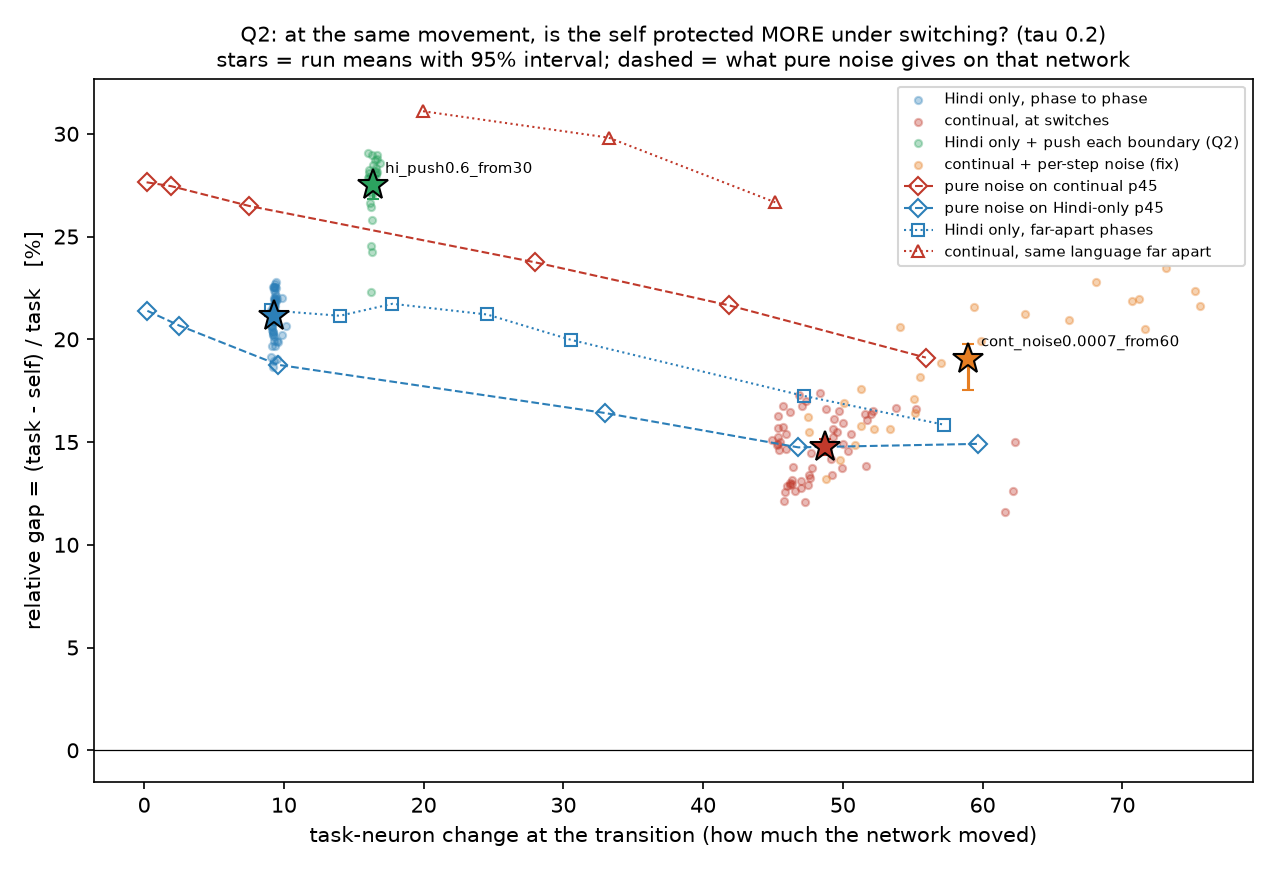

E_excess_gap


In [ ]:
for f in ["A_q2_movement_vs_gap", "E_excess_gap", "F_enc_vs_dec", "B_fix_training", "C_health", "D_q2_training"]:
    print(f); display(Image(f"analysis/v6/{f}.png"))

## 3. Lesion (mean-ablation), new runs vs references
Replace the self (or the core = self neurons that stayed across the last transition) by its mean activation; how much does the validation loss rise, compared with the same number of random task neurons?
Phases are picked automatically from what the new runs have trained.

In [5]:
fix_ph = [p for p in phases_of(FIX) if p > 60]; q2_ph = [p for p in phases_of(Q2) if p > 30]
pick = lambda ph: sorted(set(ph[::max(1, len(ph) // 4)][:3] + ph[-1:]))
fix_ph, q2_ph = pick(fix_ph), pick(q2_ph)
print("lesion phases: fix", fix_ph, "| Q2", q2_ph)
get(REF_C, fix_ph); get(REF_H, q2_ph)
run("analysis_v6_lesion.py", "--gpu", GPU, "--tau", "0.2", "--out", "lesion_fix", "--phases", ",".join(map(str, fix_ph)),
    "--runs", f"continual={REF_C},fix={FIX}")
run("analysis_v6_lesion.py", "--gpu", GPU, "--tau", "0.2", "--out", "lesion_q2", "--phases", ",".join(map(str, q2_ph)),
    "--runs", f"hindi={REF_H},push={Q2}")

fix phase 61: done in 14s
continual phase 67: done in 11s
fix phase 67: done in 12s
continual phase 73: done in 5s
fix phase 73: done in 5s
continual phase 86: done in 4s
fix phase 86: done in 4s
finished: /workspace/shreshth/analysis/v5/lesion_fix
exit code 0
tau50 per layer: {'enc0.mlp': 0.2, 'enc1.mlp': 0.2, 'enc2.mlp': 0.2, 'enc3.mlp': 0.2, 'dec0.mlp': 0.2, 'dec1.mlp': 0.2, 'dec2.mlp': 0.2, 'dec3.mlp': 0.2}
hindi phase 31: done in 13s
push phase 31: done in 13s
hindi phase 38: done in 14s
push phase 38: done in 9s
hindi phase 45: done in 14s
push phase 45: done in 8s
hindi phase 58: done in 14s
push phase 58: done in 8s
finished: /workspace/shreshth/analysis/v5/lesion_q2
exit code 0


In [6]:
import pandas as pd
pd.set_option("display.width", 200)
for name in ["lesion_fix", "lesion_q2"]:
    L = pd.read_csv(f"analysis/v5/{name}/lesion.csv")
    L["extra_vs_random"] = L.delta_group - L.delta_random_task
    print(f"\n{name}: loss rise when the group is mean-ablated (mean over layers and languages)")
    display(L.groupby(["run", "group"])[["frac_of_layer", "delta_group", "delta_random_task", "extra_vs_random"]].mean().round(3))


lesion_fix: loss rise when the group is mean-ablated (mean over layers and languages)


frac_of_layer  delta_group  delta_random_task  extra_vs_random
run       group                                                                
continual core           0.373        0.045              0.035            0.011
          self           0.431        0.029              0.024            0.006
fix       core           0.374        0.051              0.056           -0.005
          self           0.424        0.029              0.023            0.007


lesion_q2: loss rise when the group is mean-ablated (mean over layers and languages)


frac_of_layer  delta_group  delta_random_task  extra_vs_random
run   group                                                                
hindi core           0.366        0.048              0.029            0.019
      self           0.385        0.063              0.032            0.032
push  core           0.400        0.037              0.031            0.006
      self           0.446        0.039              0.042           -0.003